# BIOT 6900 · Module 5, Part 3 — Assignment


**Shreegowri M Bhojanna | DPYD | 22 October 2026**

No gene assignment was visible, so I chose DPYD for its role in fluoropyrimidine metabolism. This is a germline drug-response exercise from PART-II of the module section.

**Run notes:** Atlas is skipped (no key). Real MyVariant.info data are cached. Fetch fixes: pagination/count checks, JSON ID lists, exact-allele anchors and preservation of zero AF. The supplied first-RCV labels, calibration formula and discordance rules are retained.

**Data Snapshot:** API reports index 20250624 and ClinVar 2025-05.

Pulled RCV as well since my previous workplace use to refer to ClinVar DB a lot.

---
## Step 0 · Setup

Run this cell. It is the same machinery you used in Part 2, collected in one place: the API fields, the parsing helpers, `fetch_gene()`, `numeric()`, `clinvar_label()` and `calibrate()`.

You do not need to change anything here except `MY_GENE`.

In [1]:
import sys, time, re, json, pathlib
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)
GENES = ["CYP2C19", "CYP2C9", "VKORC1", "DPYD", "TPMT"]
MV = "https://myvariant.info/v1"
AVI_FILE = DATA / "alphagenome_avi.tsv"

ANCHORS = {"rs1799853": "CYP2C9*2", "rs1057910": "CYP2C9*3",
           "rs9923231": "VKORC1 -1639G>A", "rs4244285": "CYP2C19*2",
           "rs12248560": "CYP2C19*17", "rs3918290": "DPYD*2A",
           "rs67376798": "DPYD c.2846A>T", "rs1142345": "TPMT*3C"}

FIELDS = ",".join([
    "dbsnp.rsid",                        # the rs number
    "snpeff.ann.effect",                 # consequence term
    "cadd.phred",                        # CADD
    "dbnsfp.revel.score",                # REVEL
    "dbnsfp.alphamissense",              # AlphaMissense
    "dbnsfp.aa.ref", "dbnsfp.aa.alt", "dbnsfp.aa.pos", "dbnsfp.genename",
    "gnomad_genome.af.af", "gnomad_exome.af.af",
    "clinvar.rcv.clinical_significance",
    "clinvar.rcv.review_status",
    "clinvar.gene.symbol",
    "clinvar.variant_id", "clinvar.rcv.conditions", "clinvar.hgvs",
])

def first(x):
    """Some fields come back as a single value, some as a list. Take the first."""
    return (x[0] if x else None) if isinstance(x, list) else x

def dig(d, *path):
    """Walk a nested dict safely. Returns None if any level is missing."""
    for k in path:
        if not isinstance(d, dict):
            return None
        d = d.get(k)
        if d is None:
            return None
    return d

# ClinVar review status, as the familiar star rating
STARS = {"practice guideline": 4,
         "reviewed by expert panel": 3,
         "criteria provided, multiple submitters, no conflicts": 2,
         "criteria provided, conflicting classifications": 1,
         "criteria provided, conflicting interpretations": 1,
         "criteria provided, single submitter": 1,
         "no assertion criteria provided": 0,
         "no classification provided": 0}

# snpEff reports one effect per transcript. Keep the most severe one.
SEVERITY = ["stop_gained", "frameshift_variant", "splice_acceptor_variant",
            "splice_donor_variant", "start_lost", "stop_lost", "missense_variant",
            "splice_region_variant", "synonymous_variant", "5_prime_UTR_variant",
            "3_prime_UTR_variant", "intron_variant", "upstream_gene_variant",
            "downstream_gene_variant", "intergenic_region"]

def all_effects(h):
    """Every effect snpEff reported, across every transcript, split into single terms."""
    ann = dig(h, "snpeff", "ann")
    raw = [a.get("effect") for a in (ann if isinstance(ann, list) else [ann]) if isinstance(a, dict)]
    terms = []
    for e in raw:                       # snpEff emits compound terms joined by "&"
        if e:
            terms += [t for t in e.split("&") if t != "structural_interaction_variant"]
    return sorted(set(terms))

def worst_effect(h):
    """Collapse to ONE term: the most severe across all transcripts."""
    terms = all_effects(h)
    if not terms:
        return None
    return min(terms, key=lambda t: SEVERITY.index(t) if t in SEVERITY else 99)

def to_row(h, gene=None):
    aaref, aaalt = first(dig(h, "dbnsfp", "aa", "ref")), first(dig(h, "dbnsfp", "aa", "alt"))
    aapos = first(dig(h, "dbnsfp", "aa", "pos"))
    rcv = first(dig(h, "clinvar", "rcv")) or {}   # first condition-level RCV, as in the lab
    rev = rcv.get("review_status")
    am = dig(h, "dbnsfp", "alphamissense", "score")
    return {
        "hgvs_g":        h.get("_id"),
        "rsid":          dig(h, "dbsnp", "rsid"),
        "gene":          first(dig(h, "clinvar", "gene", "symbol")) or first(dig(h, "dbnsfp", "genename")) or gene,
        "clinvar_id":    dig(h, "clinvar", "variant_id"),
        "consequence":   worst_effect(h),
        "consequence_all": ";".join(all_effects(h)),   # keep the full picture
        "aa_change":     f"{aaref}{aapos}{aaalt}" if (aaref and aaalt and aapos) else None,
        "cadd_phred":    dig(h, "cadd", "phred"),
        "revel":         first(dig(h, "dbnsfp", "revel", "score")),
        "alphamissense": first(am) if isinstance(am, list) else am,
        "gnomad_af":     (dig(h, "gnomad_genome", "af", "af") if dig(h, "gnomad_genome", "af", "af") is not None else dig(h, "gnomad_exome", "af", "af")),
        "clinvar_sig":   rcv.get("clinical_significance"),
        "clinvar_stars": STARS.get(str(rev).lower(), 0),
    }

FORCE_REFETCH = False

# Known pharmacogenomic alleles, so we can check the fetch worked and
# recognise them later.
ANCHORS = {"rs1799853": "CYP2C9*2", "rs1057910": "CYP2C9*3",
           "rs9923231": "VKORC1 -1639G>A", "rs4244285": "CYP2C19*2",
           "rs12248560": "CYP2C19*17", "rs3918290": "DPYD*2A",
           "rs67376798": "DPYD c.2846A>T", "rs1142345": "TPMT*3C"}

ANCHOR_ALLELES = {
    "chr10:g.94942290C>T": "CYP2C9*2", "chr10:g.94981296A>C": "CYP2C9*3",
    "chr16:g.31096368C>T": "VKORC1 -1639G>A", "chr10:g.94781859G>A": "CYP2C19*2",
    "chr10:g.94761900C>T": "CYP2C19*17", "chr1:g.97450058C>T": "DPYD*2A",
    "chr1:g.97082391T>A": "DPYD c.2846A>T", "chr6:g.18130687T>C": "TPMT*3C"
}

def query_hits(gene, assembly, fields):
    hits, offset = [], 0
    while True:
        r = requests.get(f"{MV}/query", timeout=90, params={
            "q": f"clinvar.gene.symbol:{gene}", "assembly": assembly,
            "fields": fields, "size": 1000, "from": offset})
        r.raise_for_status()
        page = r.json()
        hits += page.get("hits", [])
        total = page["total"]
        if len(hits) >= total:
            break
        if not page.get("hits"):
            raise RuntimeError("Incomplete query; do not analyse this download")
        offset += len(page["hits"])
        time.sleep(0.3)
    assert len({h["_id"] for h in hits}) == total
    return hits


def fetch_gene(gene, verbose=True):
    raw = DATA / "raw"
    raw.mkdir(exist_ok=True)
    p38, p19 = raw / f"{gene}_hg38.json", raw / f"{gene}_hg19.json"
    if p38.exists() and p19.exists() and not FORCE_REFETCH:
        rows = json.loads(p38.read_text())
        hits19 = json.loads(p19.read_text())
    else:
        ids = [h["_id"] for h in query_hits(gene, "hg38", "_id")]
        rows = []
        for i in range(0, len(ids), 500):
            # A JSON list preserves IDs containing commas.
            r = requests.post(f"{MV}/variant", timeout=180, json={
                "ids": ids[i:i+500], "fields": FIELDS, "assembly": "hg38"})
            r.raise_for_status()
            rows += r.json()
            time.sleep(0.3)
        assert len(rows) == len(ids) and not any(h.get("notfound") for h in rows)
        assert {h["_id"] for h in rows} == set(ids)
        hits19 = query_hits(gene, "hg19", "clinvar.variant_id,cadd.phred")
        p38.write_text(json.dumps(rows))
        p19.write_text(json.dumps(hits19))
        from datetime import datetime, timezone
        metadata = {"gene": gene, "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
                    "hg38_total": len(ids), "hg38_unique": len(rows),
                    "hg19_total": len(hits19), "hg19_unique": len(hits19)}
        (raw / f"{gene}_fetch.json").write_text(json.dumps(metadata, indent=2))

    df = pd.DataFrame([to_row(h, gene) for h in rows])
    assert df.hgvs_g.is_unique
    cadd = {}
    for h in hits19:
        vid, ph = first(dig(h, "clinvar", "variant_id")), dig(h, "cadd", "phred")
        if vid is not None and ph is not None:
            cadd[vid] = ph
    df["cadd_phred"] = df.clinvar_id.map(cadd)
    # Keep all condition-level records for the frequency audit.
    records = [dig(h, "clinvar", "rcv") or [] for h in rows]
    records = [x if isinstance(x, list) else [x] for x in records]
    df["clinvar_sig_all"] = [" | ".join(str(r.get("clinical_significance", "")) for r in x) for x in records]
    df["rcv_count"] = [len(x) for x in records]
    df["any_drug_response"] = df.clinvar_sig_all.str.contains("drug response", case=False)
    df["note"] = df.hgvs_g.map(ANCHOR_ALLELES)
    if verbose:
        print(f"{gene}: {len(df)} hg38 records; {len(hits19)} hg19 records; no truncation")
    return df

def numeric(df):
    """Force the score columns to numbers. Strings here break everything later."""
    for c in ["cadd_phred", "revel", "alphamissense", "spliceai_dg",
              "spliceai_dl", "avi", "gnomad_af", "clinvar_stars"]:
        if c not in df.columns:
            df[c] = np.nan
        df[c] = pd.to_numeric(df[c], errors="coerce")
    return df

def clinvar_label(sig):
    if not isinstance(sig, str): return "none"
    s = sig.lower()
    if "conflict" in s: return "conflicting"
    if "pathogenic" in s and "non-pathogenic" not in s: return "P/LP"
    if "benign" in s: return "B/LB"
    if "uncertain" in s: return "VUS"
    return "other"          # includes "drug response"

STRENGTH = [(18.7, "strong, pathogenic"), (4.3, "moderate, pathogenic"),
            (2.08, "supporting, pathogenic"), (0.48, "no evidence either way"),
            (0.23, "supporting, benign"), (0.053, "moderate, benign"),
            (0.0, "strong, benign")]

def strength_for(lr):
    if lr != lr: return "undefined"
    for cut, name in STRENGTH:
        if lr >= cut: return name
    return "strong, benign"

def calibrate(df, score_col, bands):
    d = df[df.label.isin(["P/LP", "B/LB"]) & df[score_col].notna()].copy()
    d["band"] = pd.cut(d[score_col], bands)
    n_p, n_b = (d.label == "P/LP").sum(), (d.label == "B/LB").sum()
    g = d.groupby("band", observed=False)
    out = pd.DataFrame({"n": g.size(),
                        "n_PLP": g.label.apply(lambda s: (s == "P/LP").sum()),
                        "n_BLB": g.label.apply(lambda s: (s == "B/LB").sum())})
    with np.errstate(divide="ignore", invalid="ignore"):
        out["LR+"] = ((out.n_PLP / max(n_p, 1)) / (out.n_BLB / max(n_b, 1))).round(2)
    out["evidence"] = out["LR+"].map(strength_for)
    out.attrs["n_p"], out.attrs["n_b"] = n_p, n_b
    return out

print("helpers loaded:", ", ".join(["fetch_gene", "numeric", "to_row", "clinvar_label",
                                    "calibrate", "strength_for", "worst_effect"]))
from IPython.display import display
RESULTS = pathlib.Path("results"); RESULTS.mkdir(exist_ok=True)


helpers loaded: fetch_gene, numeric, to_row, clinvar_label, calibrate, strength_for, worst_effect


In [2]:
MY_GENE = "DPYD"  # No assigned gene found. Chosen for oncology relevance.
assert MY_GENE in GENES
MY_FILE = DATA / f"{MY_GENE}.tsv"
print("working on", MY_GENE)


working on DPYD


---
## Q1 · Fetch and quality-check your gene  (15 points)

Part 2 fetched five genes for you to read. Now do it for yours, and then **check what came back**. A truncated or empty fetch is the failure mode that silently ruins everything downstream, and it does not raise an error.

**Cache your result** to `data/<YOUR_GENE>.tsv` and load from there on later runs. Re-downloading on every `Restart & Run All` is slow and is poor practice against a free public API.

**Three quality checks you must run and report:**

1. **Count.** How many variants came back? A gene with 3 variants means your query string is wrong.
2. **Anchors.** Did the known star allele for your gene appear? `ANCHORS` lists them. If your gene has one and it is missing, your fetch is incomplete.
3. **Score columns.** Are CADD, REVEL and gnomAD populated at all, or did everything come back empty?

In [3]:
if MY_FILE.exists() and not FORCE_REFETCH:
    G = pd.read_csv(MY_FILE, sep="\t")
else:
    G = fetch_gene(MY_GENE)
    G.to_csv(MY_FILE, sep="\t", index=False)
G = numeric(G)
G["label"] = G.clinvar_sig.map(clinvar_label)
G["note"] = G.hgvs_g.map(ANCHOR_ALLELES)
assert G.hgvs_g.is_unique and G.gene.eq(MY_GENE).all()
meta = json.loads((DATA / "raw" / f"{MY_GENE}_fetch.json").read_text())
assert len(G) == meta["hg38_total"] == meta["hg38_unique"]
expected = {k: v for k, v in ANCHOR_ALLELES.items() if v.startswith(MY_GENE)}
missing = set(expected) - set(G.hgvs_g)
assert not missing, f"Missing anchor alleles: {missing}"
print("Variants:", len(G), "| anchors:", len(expected), "of", len(expected))
print("Retrieved:", meta["retrieved_at_utc"]) #Re-ran before submitting to gitHub
print("Non-missing scores/AF:")
print(G[["cadd_phred", "revel", "alphamissense", "gnomad_af"]].count())
assert G[["cadd_phred", "revel", "gnomad_af"]].notna().any().all()
display(G[G.hgvs_g.isin(expected)][["hgvs_g", "rsid", "note", "consequence", "cadd_phred", "revel", "gnomad_af"]])
print("First-RCV labels:", G.label.value_counts().to_dict())
print("Rows with multiple condition records:", int((G.rcv_count > 1).sum()))
G[G.rcv_count > 1].to_csv(RESULTS / "clinvar_record_audit.csv", index=False)
source_file = DATA / "myvariant_hg38_metadata.json"
if source_file.exists():
    source = json.loads(source_file.read_text())
    print("Cached index:", source.get("build_version"), "| ClinVar source:", source.get("src", {}).get("clinvar", {}).get("version"))


DPYD: 426 hg38 records; 426 hg19 records; no truncation
Variants: 426 | anchors: 2 of 2
Retrieved: 2026-10-22T17:12:13.595945+00:00
Non-missing scores/AF:
cadd_phred       304
revel            161
alphamissense    163
gnomad_af        273
dtype: int64


,hgvs_g,rsid,note,consequence,cadd_phred,revel,gnomad_af
158,chr1:g.97450058C>T,rs3918290,DPYD*2A,splice_donor_variant,23.7,NaN,0.004555
308,chr1:g.97082391T>A,rs67376798,DPYD c.2846A>T,missense_variant,29.9,0.962,0.003280


First-RCV labels: {'VUS': 183, 'P/LP': 106, 'B/LB': 103, 'other': 28, 'conflicting': 6}
Rows with multiple condition records: 92


---
## Q2 · Audit tool coverage  (10 points)

Work out what fraction of your gene's variants each tool could score, broken down by consequence class. You will be asked about the gaps in the report.

Use `TOOLS = ["cadd_phred", "revel", "alphamissense"]`, and add `"avi"` if you ran the Atlas in Q5.

,n_variants,cadd_phred,revel,alphamissense
consequence,,,,
3_prime_UTR_variant,34,11,0,0
frameshift_variant,29,0,0,0
intron_variant,53,44,0,0
missense_variant,163,161,161,163
splice_acceptor_variant,16,2,0,0
splice_donor_variant,17,4,0,0
splice_region_variant,7,4,0,0
stop_gained,30,29,0,0
synonymous_variant,48,47,0,0


,scored,percent
cadd_phred,304,71.4
revel,161,37.8
alphamissense,163,38.3


Zero REVEL: ['3_prime_UTR_variant', 'frameshift_variant', 'intron_variant', 'splice_acceptor_variant', 'splice_donor_variant', 'splice_region_variant', 'stop_gained', 'synonymous_variant', 'unannotated', 'upstream_gene_variant']


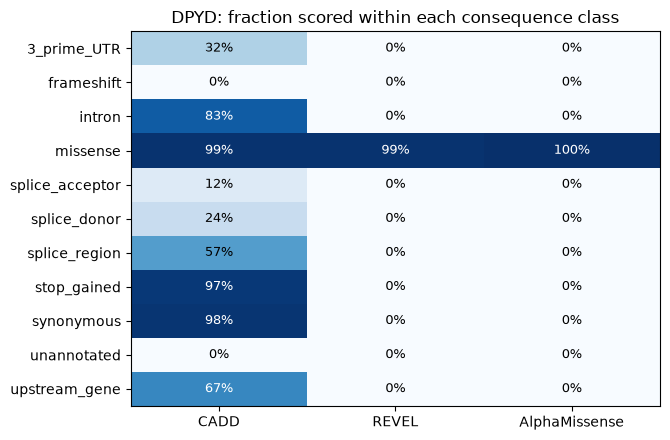

In [4]:
TOOLS = ["cadd_phred", "revel", "alphamissense"]
coverage = G.assign(consequence=G.consequence.fillna("unannotated")).groupby("consequence")[TOOLS].count()
coverage.insert(0, "n_variants", G.consequence.fillna("unannotated").value_counts())
overall = pd.DataFrame({"scored": G[TOOLS].count(), "percent": (100 * G[TOOLS].notna().mean()).round(1)})
display(coverage)
display(overall)
print("Zero REVEL:", coverage.index[coverage.revel.eq(0)].tolist())
coverage.to_csv(RESULTS / "coverage_by_consequence.csv")
overall.to_csv(RESULTS / "coverage_overall.csv")
frac = coverage[TOOLS].div(coverage.n_variants, axis=0)
fig, ax = plt.subplots(figsize=(6.8, 4.5))
im = ax.imshow(frac, vmin=0, vmax=1, cmap="Blues", aspect="auto")
ax.set_xticks(range(3), ["CADD", "REVEL", "AlphaMissense"])
ax.set_yticks(range(len(frac)), frac.index.str.replace("_variant", "", regex=False))
for i in range(len(frac)):
    for j in range(3):
        ax.text(j, i, f"{frac.iloc[i,j]:.0%}", ha="center", va="center", color="white" if frac.iloc[i,j] > .6 else "black", fontsize=9)
ax.set_title("DPYD: fraction scored within each consequence class")
fig.tight_layout()
fig.savefig(RESULTS / "coverage_dpyd.png", dpi=180, bbox_inches="tight")
plt.show()


---
## Q3 · Frequency filter, with a threshold you can defend  (15 points)

Choose a maximum credible allele frequency for your gene and **justify it from the biology of this gene and the drugs it affects**, not from habit.

**A warning specific to pharmacogenes.** Reduced-function pharmacogene alleles are frequently **common**. CYP2C19\*2 sits around 15% in many populations and VKORC1 −1639G>A near 40% in some. A rare-disease filter of 0.1% would discard the most clinically important variants in these genes.

Whatever threshold you pick, you must inspect what it throws away.

In [15]:
display(G[["rsid", "hgvs_g", "gnomad_af", "clinvar_sig"]]
        .sort_values("gnomad_af", ascending=False).head(20))

,rsid,hgvs_g,gnomad_af,clinvar_sig
134,rs290854,chr1:g.97082275G>A,0.999980,Benign
46,rs2786511,chr1:g.97692035C>T,0.997305,Benign
366,rs290855,chr1:g.97079215T>C,0.802343,Benign
222,rs2811178,chr1:g.97515686T>C,0.617752,Benign
18,rs1337752,chr1:g.97516150C>T,0.616676,Benign
179,rs6699630,chr1:g.97373857C>G,0.505139,Benign
140,rs291592,chr1:g.97078208C>T,0.451997,Benign
309,rs291593,chr1:g.97078196G>A,0.289780,Benign
425,rs1801265,chr1:g.97883329A>G,0.273227,Pathogenic
100,rs1890138,chr1:g.97373460A>G,0.262964,Benign


In [16]:
MAX_AF = 1.0  # Deliberate NO-frequency-exclusion policy - Keeping the full PGx inventory; frequency alone cannot exclude drug response.
G_all = G.copy()
assert G.gnomad_af.dropna().between(0, 1).all()
# Flags are screening annotations, NOT confirmed impaired drug metabolism.
important_flag = (G.label.eq("P/LP") | G.clinvar_sig_all.fillna("").str.contains("drug response", case=False))
# CPIC-recognised DPYD alleles for a biologically specific sensitivity check.
core_pgx = G.rsid.astype(str).isin(["rs3918290", "rs55886062", "rs67376798", "rs75017182"])
columns = ["hgvs_g", "rsid", "note", "gnomad_af", "clinvar_sig", "clinvar_sig_all"]
for threshold, name in [(MAX_AF, "chosen_no_exclusion"), (0.01, "one_percent"), (0.001, "rare_disease")]:
    removed = G[G.gnomad_af.gt(threshold)]
    flagged = G[G.gnomad_af.gt(threshold) & important_flag]
    core_lost = G[G.gnomad_af.gt(threshold) & core_pgx]
    print(f"{name}: AF > {threshold:g}; removed {len(removed)}; "
          f"flagged P/LP or drug-response {len(flagged)}; "
          f"CPIC-recognised DPYD alleles lost {len(core_lost)}")
    display(flagged[columns])
    if len(core_lost):
        print("Known functional alleles removed:")
        display(core_lost[columns])
    removed.to_csv(RESULTS / f"af_removed_{name}.csv", index=False)

print("Missing AF retained:", int(G.gnomad_af.isna().sum()))
G = G[G.gnomad_af.isna() | G.gnomad_af.le(MAX_AF)].copy()
print("Retained:", len(G))


chosen_no_exclusion: AF > 1; removed 0; flagged P/LP or drug-response 0; CPIC-recognised DPYD alleles lost 0


,hgvs_g,rsid,note,gnomad_af,clinvar_sig,clinvar_sig_all


one_percent: AF > 0.01; removed 50; flagged P/LP or drug-response 7; CPIC-recognised DPYD alleles lost 1


,hgvs_g,rsid,note,gnomad_af,clinvar_sig,clinvar_sig_all
1,chr1:g.97515839T>C,rs1801159,NaN,0.185911,Benign,Benign | Benign | Benign | drug response | dru...
24,chr1:g.97573863C>T,rs56038477,NaN,0.013112,Benign,Benign | Benign | Likely benign | drug respons...
76,chr1:g.97699535T>C,rs2297595,NaN,0.080138,Benign,Benign | Benign | Conflicting interpretations ...
137,chr1:g.97515865C>T,rs1801158,NaN,0.013716,Benign/Likely benign,Benign/Likely benign | Benign | Conflicting in...
224,chr1:g.97450068A>G,rs17376848,NaN,0.043817,not provided,not provided | Benign | Benign | drug response...
281,chr1:g.97579893G>C,rs75017182,NaN,0.013111,drug response,drug response | drug response | drug response ...
425,chr1:g.97883329A>G,rs1801265,NaN,0.273227,Pathogenic,Pathogenic | Benign | drug response | drug res...


Known functional alleles removed:


...

rare_disease: AF > 0.001; removed 69; flagged P/LP or drug-response 10; CPIC-recognised DPYD alleles lost 3


,hgvs_g,rsid,note,gnomad_af,clinvar_sig,clinvar_sig_all
1,chr1:g.97515839T>C,rs1801159,NaN,0.185911,Benign,Benign | Benign | Benign | drug response | dru...
24,chr1:g.97573863C>T,rs56038477,NaN,0.013112,Benign,Benign | Benign | Likely benign | drug respons...
76,chr1:g.97699535T>C,rs2297595,NaN,0.080138,Benign,Benign | Benign | Conflicting interpretations ...
137,chr1:g.97515865C>T,rs1801158,NaN,0.013716,Benign/Likely benign,Benign/Likely benign | Benign | Conflicting in...
158,chr1:g.97450058C>T,rs3918290,DPYD*2A,0.004555,Pathogenic/Likely pathogenic,Pathogenic/Likely pathogenic | Pathogenic | Co...
187,chr1:g.97699474T>C,rs115232898,NaN,0.005799,Benign,Benign | Conflicting interpretations of pathog...
224,chr1:g.97450068A>G,rs17376848,NaN,0.043817,not provided,not provided | Benign | Benign | drug response...
281,chr1:g.97579893G>C,rs75017182,NaN,0.013111,drug response,drug response | drug response | drug response ...
308,chr1:g.97082391T>A,rs67376798,DPYD c.2846A>T,0.003280,Conflicting interpretations of pathogenicity,Conflicting interpretations of pathogenicity |...
425,chr1:g.97883329A>G,rs1801265,NaN,0.273227,Pathogenic,Pathogenic | Benign | drug response | drug res...


Known functional alleles removed:


,hgvs_g,rsid,note,gnomad_af,clinvar_sig,clinvar_sig_all
158,chr1:g.97450058C>T,rs3918290,DPYD*2A,0.004555,Pathogenic/Likely pathogenic,Pathogenic/Likely pathogenic | Pathogenic | Co...
281,chr1:g.97579893G>C,rs75017182,NaN,0.013111,drug response,drug response | drug response | drug response ...
308,chr1:g.97082391T>A,rs67376798,DPYD c.2846A>T,0.003280,Conflicting interpretations of pathogenicity,Conflicting interpretations of pathogenicity |...


Missing AF retained: 153
Retained: 426


---
## Q4 · Calibrate a predictor into evidence  (15 points)

Pick the predictor with the best coverage of your gene and calibrate it with `calibrate()`, as in Part 2 Section 8. Report the likelihood ratio and the implied evidence strength per band.

Then **look hard at the denominators**. A likelihood ratio computed on four variants is not evidence; it is noise with a decimal point.

**If your gene has too few labelled variants to calibrate**, which is a real possibility for the smaller genes, do not force it. Fetch a second gene and pool, or state that calibration is not possible for your gene and explain why. Either is acceptable if you **disclose it**.

In [6]:
SCORE_COL = "cadd_phred"
BANDS = [0, 10, 20, 25, 30, 50]
calibration = calibrate(G, SCORE_COL, BANDS)
scored = G[G.label.isin(["P/LP", "B/LB"]) & G[SCORE_COL].notna()]
assert pd.cut(scored[SCORE_COL], BANDS).notna().all(), "A score falls outside the bands"
print("Labelled total:", int(G.label.isin(["P/LP", "B/LB"]).sum()))
print("Scored labels: P/LP =", calibration.attrs["n_p"], "; B/LB =", calibration.attrs["n_b"])
calibration["small_band"] = calibration.n < 10
display(calibration)
print("Bands below n=10:", int(calibration.small_band.sum()))
print("Zero and infinite LRs reflect empty class cells, not certainty.")
print("This is within-sample, mixed-consequence calibration; not a validated PGx classifier.")
calibration.to_csv(RESULTS / "calibration_cadd.csv")
# A transparent sensitivity check for the first-RCV simplification.
well_reviewed = calibrate(G[G.clinvar_stars >= 2], SCORE_COL, BANDS)
print("Two-star sensitivity: P/LP =", well_reviewed.attrs["n_p"], "; B/LB =", well_reviewed.attrs["n_b"])
display(well_reviewed)
well_reviewed.to_csv(RESULTS / "calibration_two_star.csv")

print("Consequence mix in the highest band:")
print(pd.crosstab(scored.loc[scored[SCORE_COL].gt(30), "consequence"], scored.loc[scored[SCORE_COL].gt(30), "label"]))



Labelled total: 209
Scored labels: P/LP = 39 ; B/LB = 97


,n,n_PLP,n_BLB,LR+,evidence,small_band
band,,,,,,
"(0, 10]",66,0,66,0.00,"strong, benign",False
"(10, 20]",24,0,24,0.00,"strong, benign",False
"(20, 25]",11,5,6,2.07,no evidence either way,False
"(25, 30]",4,3,1,7.46,"moderate, pathogenic",True
"(30, 50]",31,31,0,inf,"strong, pathogenic",False


Bands below n=10: 1
Zero and infinite LRs reflect empty class cells, not certainty.
This is within-sample, mixed-consequence calibration; not a validated PGx classifier.
Two-star sensitivity: P/LP = 13 ; B/LB = 29


,n,n_PLP,n_BLB,LR+,evidence
band,,,,,
"(0, 10]",20,0,20,0.00,"strong, benign"
"(10, 20]",5,0,5,0.00,"strong, benign"
"(20, 25]",6,2,4,1.12,no evidence either way
"(25, 30]",1,1,0,inf,"strong, pathogenic"
"(30, 50]",10,10,0,inf,"strong, pathogenic"


Consequence mix in the highest band:
label             P/LP
consequence           
missense_variant     4
stop_gained         27


In [17]:
# Check what consequence classes drive each likelihood ratio.
# The highest CADD band is dominated by stop-gained variants; it cannot automatically be used to reclassify missense or splicing VUS.
band_context = scored.assign(band=pd.cut(scored[SCORE_COL], BANDS))
band_by_consequence = pd.crosstab(
    [band_context["band"], band_context["consequence"].fillna("unannotated")],
    band_context["label"])
print("Calibration composition by band and consequence:")
display(band_by_consequence)
band_by_consequence.to_csv(RESULTS / "calibration_consequence_audit.csv")

Calibration composition by band and consequence:


label                             B/LB  P/LP
band     consequence                        
(0, 10]  3_prime_UTR_variant         5     0
         intron_variant             26     0
         missense_variant            6     0
         splice_region_variant       1     0
         synonymous_variant         26     0
         upstream_gene_variant       2     0
(10, 20] intron_variant             10     0
         missense_variant            2     0
         synonymous_variant         12     0
(20, 25] missense_variant            6     1
         splice_acceptor_variant     0     2
         splice_donor_variant        0     2
(25, 30] missense_variant            1     2
         splice_donor_variant        0     1
(30, 50] missense_variant            0     4
         stop_gained                 0    27

---
## Q5 · Classify the uncertain variants and export  (5 points)

Take the VUS rows in your gene, apply your calibrated evidence, and export the result.

**This is the entire point of calibration.** A VUS whose score falls in a band with an LR near 1 **stays a VUS**, because the predictor genuinely told you nothing. Only a large or small LR should move anything.

In [18]:
vus = G[G.label.eq("VUS")].copy()
vus["band"] = pd.cut(vus[SCORE_COL], BANDS)
vus["evidence"] = vus.band.map(calibration.evidence).astype(object).fillna("unscored")
vus["band_n"] = vus.band.map(calibration.n).astype(float)
vus["band_LR"] = vus.band.map(calibration["LR+"]).astype(float)
vus["raw_direction"] = np.select(
    [vus.evidence.str.contains("pathogenic"), vus.evidence.str.contains("benign")],
    ["towards pathogenic", "towards benign"], default="unchanged")
print("Course band mapping:", vus.raw_direction.value_counts().to_dict())
# Keep sparse bands from driving even a provisional direction.
vus["direction"] = vus.raw_direction.where(vus.band_n.ge(10), "unchanged")
vus["provisional_call"] = "VUS; " + vus.direction
vus.loc[vus.band_n.lt(10), "provisional_call"] = "VUS; unchanged (sparse calibration band)"
vus.loc[vus[SCORE_COL].isna(), "provisional_call"] = "VUS; unchanged (unscored)"
print("After n<10 safeguard:", vus.direction.value_counts().to_dict())
vus["clinical_classification"] = "VUS (unchanged)"
print("Clinical reclassifications: 0. Directions are exploratory only (Offcourse!).")
columns = ["rsid", "gene", "consequence", "aa_change", SCORE_COL, "gnomad_af", "evidence", "provisional_call",
           "hgvs_g", "clinvar_id", "clinvar_sig", "band", "band_n", "band_LR", "raw_direction", "direction", "clinical_classification"]
vus[columns].to_csv(f"pgx_classified_{MY_GENE}.csv", index=False)
print("Saved", f"pgx_classified_{MY_GENE}.csv", "| rows:", len(vus))


Course band mapping: {'unchanged': 74, 'towards benign': 56, 'towards pathogenic': 53}
After n<10 safeguard: {'unchanged': 105, 'towards benign': 56, 'towards pathogenic': 22}
Clinical reclassifications: 0. Directions are exploratory only (Offcourse!).
Saved pgx_classified_DPYD.csv | rows: 183


---
## Q6 · The Atlas and the disagreements  (code given; your writing is graded in the report)

Run both cells. The first queries the AlphaGenome Atlas for your gene; the second applies the discordance rules from Part 2 Section 10.

**If you do not have an AlphaGenome key**, set `SKIP_ATLAS = True`. The second cell still works and you answer the Atlas part of the report from reasoning. No marks are lost for a disclosed skip.

In [19]:
SKIP_ATLAS   = True  # No API key; disclosed fallback.
MAX_VARIANTS = 200

import os
ATLAS_STATUS = "not run"

def to_variant_string(hgvs):
    """Atlas wants 1-based GRCh38 chr:pos:ref>alt. It does NOT accept rsIDs."""
    m = re.match(r"(chr[\w]+):g\.(\d+)([ACGT])>([ACGT])", str(hgvs))
    return f"{m.group(1)}:{m.group(2)}:{m.group(3)}>{m.group(4)}" if m else None

if SKIP_ATLAS:
    print("SKIPPED. Disclose this in your report and answer Q6.2 from reasoning.")
    ATLAS_STATUS = "skipped"
else:
    try:
        from alphagenome.atlas import atlas
        from alphagenome.data import genome
        key = os.environ.get("ALPHAGENOME_API_KEY") or os.environ.get("ALPHA_GENOME_API_KEY")
        if not key:
            raise RuntimeError(
                "No API key in your environment. Did you relaunch Jupyter from a NEW\n"
                "  terminal after setting it? Check with:\n"
                "    import os; print(bool(os.environ.get('ALPHAGENOME_API_KEY')))\n"
                "  Or set SKIP_ATLAS = True.")
        client = atlas.create(key, timeout=30)

        pri = G.assign(_nc=~G.consequence.fillna("").str.contains("missense")) \
               .sort_values("_nc", ascending=False).head(MAX_VARIANTS)
        rows, errs = [], 0
        for n, (_, r) in enumerate(pri.iterrows(), 1):
            vs = to_variant_string(r.hgvs_g)
            if not vs:
                continue
            try:
                res = client.query_variant(
                    genome.Variant.from_str(vs),
                    requested_scorers=["AVI_SCORE", "AVI_SCORE_FEATURE_IMPORTANCE"])
                ad = res["AVI_SCORE"]
                cdf = float(ad.layers["quantiles"][0, 0])
                fi = res["AVI_SCORE_FEATURE_IMPORTANCE"]
                rows.append({"rsid": r.rsid,
                             "avi_phred": round(-10*np.log10(max(1-cdf, 1e-12)), 2),
                             "top_feature": fi.var["name"].values[int(np.argmax(np.abs(fi.X[0])))]})
            except Exception:
                errs += 1
            if n % 50 == 0:
                print(f"  {n}/{len(pri)} queried", flush=True)

        avi = pd.DataFrame(rows)
        if len(avi):
            avi.to_csv(DATA / f"avi_{MY_GENE}.tsv", sep="\t", index=False)
            G = G.merge(avi, on="rsid", how="left")
            G["avi"] = G.avi_phred
            ATLAS_STATUS = "queried live"
            print(f"\nscored {len(avi)} variants ({errs} failures)")
    except ImportError:
        print('alphagenome not installed. pip install "alphagenome>=0.9.0", then restart.')
        print("Or set SKIP_ATLAS = True.")
    except Exception as e:
        print(f"{type(e).__name__}: {e}")

if "avi" not in G.columns: G["avi"] = np.nan
if "top_feature" not in G.columns: G["top_feature"] = np.nan
G["avi"] = pd.to_numeric(G["avi"], errors="coerce")

if G.avi.notna().sum() > 0:
    a = G[G.avi.notna()]
    cols = [c for c in ["rsid", "consequence", "avi_phred", "top_feature",
                        "revel", "cadd_phred", "label"] if c in a.columns]
    print(f"\nhighest-impact {MY_GENE} variants by AVI\n")
    print(a.sort_values("avi", ascending=False)[cols].head(10).to_string(index=False))
    print("\nwhat is driving the scores (read this BEFORE the numbers)")
    print(a.top_feature.value_counts().head(8).to_string())
else:
    nc = G[~G.consequence.fillna("").str.contains("missense")]
    print(f"\nnon-missense variants in {MY_GENE}, which is what the Atlas is for: {len(nc)}")
    print(nc.consequence.value_counts().to_string())

print(f"\n[Atlas status: {ATLAS_STATUS}]")

SKIPPED. Disclose this in your report and answer Q6.2 from reasoning.

non-missense variants in DPYD, which is what the Atlas is for: 263
consequence
intron_variant             53
synonymous_variant         48
3_prime_UTR_variant        34
stop_gained                30
frameshift_variant         29
splice_donor_variant       17
splice_acceptor_variant    16
splice_region_variant       7
upstream_gene_variant       3

[Atlas status: skipped]


In [21]:
d = G.copy()
coding = d.consequence.isin(["missense_variant", "synonymous_variant"])

d["flag_cadd_vs_revel"]  = (d.cadd_phred > 25) & (d.revel < 0.35)
d["flag_revel_vs_am"]    = (d.revel - d.alphamissense).abs() > 0.4
d["flag_scored_but_vus"] = (d.label == "VUS") & (d.revel > 0.7)
d["flag_common_but_plp"] = (d.gnomad_af > 0.01) & d.label.eq("P/LP")
# Drug-response annotations are not synonyms for pathogenicity or decreased function but in lab reports for the cancer panels who do report drug response variants as well and we call them out as such
d["flag_common_drug_response"] = (d.gnomad_af > 0.01) & d.any_drug_response.fillna(False)
d["flag_no_tool_at_all"] = d[["revel", "alphamissense", "cadd_phred"]].isna().all(axis=1)
if d.avi.notna().any():
    d["flag_atlas_only"] = (d.avi > 20) & d.revel.isna() & d.alphamissense.isna()

flags = [c for c in d.columns if c.startswith("flag_")]
print(f"discordant variants in {MY_GENE}\n")
print(d[flags].sum().to_string())

hits = d[d[flags].any(axis=1)]
cols = [c for c in ["rsid", "note", "consequence", "consequence_all", "aa_change",
                    "cadd_phred", "revel", "alphamissense", "avi", "gnomad_af",
                    "label"] if c in d.columns]
print(f"\n{len(hits)} variants trip at least one rule\n")
print(hits[cols].head(15).to_string(index=False) if len(hits) else "  (none)")

if len(hits) == 0:
    print("\nINTERESTING, IF SO EXPLORE WHY...")
hits.to_csv(RESULTS / "discordant_dpyd.csv", index=False)
d[flags].sum().to_csv(RESULTS / "discordance_counts.csv", header=["n_variants"])
focus = d[d.hgvs_g.eq("chr1:g.97082391T>A")]
print("\nSelected case: NM_000110.4:c.2846A>T (p.Asp949Val)")
display(focus[cols + flags])

# Separate genuine disagreements between numeric predictors from missing-coverage flags.
pred_disagree = d["flag_cadd_vs_revel"] | d["flag_revel_vs_am"]
print("!!Direct predictor-disagreement cases!!:", int(pred_disagree.sum()))
print("No-tool-coverage cases (not disagreements):", int(d["flag_no_tool_at_all"].sum()))

# Clinical splicing control relevant to Q6.2. This is a deep-intronic HapB3 allele.
display(G.loc[G.rsid.eq("rs75017182"),
              ["rsid", "hgvs_g", "consequence", "cadd_phred", "revel",
               "alphamissense", "gnomad_af", "clinvar_sig_all"]])


discordant variants in DPYD

flag_cadd_vs_revel             0
flag_revel_vs_am              35
flag_scored_but_vus           40
flag_common_but_plp            1
flag_common_drug_response      7
flag_no_tool_at_all          120

187 variants trip at least one rule

        rsid note             consequence                        consequence_all aa_change  cadd_phred  revel  alphamissense  avi  gnomad_af label
   rs1801159  NaN        missense_variant                       missense_variant     I543V       9.639  0.123         0.0621  NaN   0.185911  B/LB
rs1057516713  NaN splice_acceptor_variant intron_variant;splice_acceptor_variant       NaN         NaN    NaN            NaN  NaN   0.000007  P/LP
 rs115349832  NaN          intron_variant                         intron_variant       NaN         NaN    NaN            NaN  NaN        NaN other
rs1349131310  NaN      synonymous_variant      intron_variant;synonymous_variant       NaN         NaN    NaN            NaN  NaN        NaN  B/LB


,rsid,note,consequence,consequence_all,aa_change,cadd_phred,revel,alphamissense,avi,gnomad_af,label,flag_cadd_vs_revel,flag_revel_vs_am,flag_scored_but_vus,flag_common_but_plp,flag_common_drug_response,flag_no_tool_at_all
308,rs67376798,DPYD c.2846A>T,missense_variant,missense_variant,D949V,29.9,0.962,0.2925,NaN,0.00328,conflicting,False,True,False,False,False,False


!!Direct predictor-disagreement cases!!: 35
No-tool-coverage cases (not disagreements): 120


,rsid,hgvs_g,consequence,cadd_phred,revel,alphamissense,gnomad_af,clinvar_sig_all
281,rs75017182,chr1:g.97579893G>C,intron_variant,0.378,NaN,NaN,0.013111,drug response | drug response | drug response ...


---
## Q6 · Your report  (40 points)

Write **3 to 4 pages** answering the four questions below. Marks are for reasoning, not for reaching a particular conclusion. A confident, clearly argued wrong answer scores better than a hedged list of possibilities.

### 6.1 · Thresholds and calibration  (10 points)

Which allele-frequency threshold did you choose in Q3, and why is it right for *this gene* rather than for a rare-disease gene? What did your 0.001 contrast discard? Which predictor did you calibrate and why that one? Report the likelihood ratios, state how many labelled variants they rest on, and say what that does to your confidence in them.

### 6.2 · Coverage gaps and the regulatory genome  (10 points)

Which consequence classes in your gene could no missense predictor score? Pick **one specific unscored variant**, name it, and say what evidence you would need to classify it and which tool or assay would produce that evidence.

Then address the Atlas. If you ran it: what did it add, and what did the `top_feature` attributions say was driving the top scores? Remember that a score driven by `CACTUS_241_WAY` means conservation is carrying it and the mechanism is unresolved, which is weaker than one driven by `MAX_ABS_DNASE`. If you did not run it: say what it could in principle have told you about which specific variants in your gene, and why nothing else in the course can.

### 6.3 · A discordant variant, read mechanistically  (12 points)

Choose **one** variant from the Q6 discordance output. State which rule it tripped, what each tool said about it, and what biology could produce that pattern. Argue for one explanation over the alternatives.

The question to answer is not *which tool is right*. It is *what would have to be true about this variant for both outputs to make sense*.

### 6.4 · What you could not determine  (8 points)

Name **two** things your analysis cannot establish about your most interesting variant, drawing on the lecture's list: penetrance, mechanism and direction, zygosity and phase, tissue and timing, modifiers including phenoconversion, and clinical utility.

Then name the **single experiment or dataset** that would resolve your most interesting call, and say what result would change your mind.

---
## Report rubric

Each of the four questions is marked on the same four-level scale, scaled to its point value.

| Level | What it looks like |
|---|---|
| **Excellent** (90-100% of the points) | Answers the question directly with specifics from *their own* output. Names variants, quotes their own numbers. Commits to an interpretation and defends it. Acknowledges the limits of the evidence without hiding behind them. |
| **Good** (75-89%) | Correct and specific, but stops short of an argument. Describes what the numbers are rather than what they mean. Limitations listed rather than weighed. |
| **Developing** (55-74%) | Generic. Could have been written without running the notebook. Repeats lecture phrasing rather than engaging with this gene. Numbers quoted without interpretation, or interpretation offered without numbers. |
| **Insufficient** (<55%) | Does not answer the question asked, contradicts their own output, or treats a predictor score as a verdict about a patient. |

**Across all four questions, these specifically earn credit:**

- Quoting your own numbers rather than the ones in the lab guide
- Naming a specific variant rather than describing a category
- Disclosing a fallback and explaining its cost
- Distinguishing *could not score* from *scored and found nothing*

**And these specifically lose it:**

- Treating a blank score as a benign result
- Reporting a likelihood ratio from a tiny band without caveat
- Calling a variant pathogenic on the strength of predictor scores alone
- Listing possible explanations instead of arguing for one

### My interpretation

- **AF:** I used 1.0 to keep the full PGx inventory. This is a no-exclusion policy, not a disease-frequency estimate. The 0.001 comparison shows what a rare-disease rule would lose.
- **Calibration:** CADD covers the most variants. Sparse bands and zero/infinite LRs limit confidence. The table mixes disease labels and consequence classes; it does not calibrate chemotherapy toxicity.
- **Coverage:** rs75017182 is deep intronic and unscored by both missense tools. Its low CADD does not exclude a splice effect. Atlas/SpliceAI could generate a splicing hypothesis; RNA evidence would test it.
- **Disagreement:** rs67376798 has REVEL 0.962 versus AlphaMissense 0.2925. I favour partial enzyme impairment, supported by published functional evidence, rather than complete loss or no effect.
- **Next evidence:** matched wild-type/D949V enzyme kinetics with 5-FU. Reproducibly normal activity would challenge my reduced-function interpretation.

References: Amstutz et al., doi:10.1002/cpt.911; Offer et al., doi:10.1158/0008-5472.CAN-13-2482; NCBI ClinVar identifiers;